# Visión por Computador - Práctica 2 - Deep Learning en Computer Vision

#### 15 puntos   |   Fecha de entrega: 7 de Diciembre, 23:59   |   Forma de entrega: a través de la tarea creada en https://pradogrado2526.ugr.es/

### Estudiante: Jose María Martín Martín

## Normas de desarrollo y entrega de la práctica

1. Para este trabajo, al igual que para los demás, se debe presentar código, resultados, discusión de los mismos, y presentación y análisis del trabajo realizado, todo integrado en el propio Google Colab Notebook (es decir, no se entrega ninguna memoria separada en `.pdf` ni ningún código `.py`). Se recuerda que código y resultados sin informe explicativo no puntúa. Resulta también fundamental recordar que solo se acepta la entrega de ficheros `.ipynb` (no resulta válido entregar un fichero `.py`).

2. En relación con el punto anterior, se recuerda que se proporciona un Notebook, denominado `Ejemplo_Otsu.ipynb`, que muestra un ejemplo de respuesta y solución a un potencial ejercicio. El propósito de este Notebook es servir de referencia al alumnado acerca de cómo responder los ejercicios planteados. Véase que, por ejemplo, en aras de diferenciar con facilidad enunciados y respuestas, estas últimas se presentan en otro color (azul, en ese caso).

3. El diseño de celdas del documento debe ser respetado. Es decir, no se puede modificar el orden de los ejercicios o alterar la estructura del Notebook, de forma que dificulte localizar los contenidos. Aunque sí se puede, por ejemplo, crear nuevas subsecciones dentro de las secciones ya existentes para estructurar y organizar con más claridad las respuestas, así como para incluir los experimentos extra que se deseen.

4. Tal y como se muestra en `Ejemplo_Otsu.ipynb`, no hay ningún problema en emplear técnicas de IA generativa (como ChatGPT o Gemini) para crear el código de los distintos ejercicios o para enriquecer el análisis y descripción del trabajo realizado (aunque, obvia decirlo, su uso no es obligatorio). Pero, en caso de usarse, sí se debe aclarar de qué modo se ha usado la IA, con qué objetivo, y se debe demostrar que se entiende perfectamente lo que se ha hecho.

5. Solo se entregará el fichero `.ipynb` (incorporando código, resultados, y explicación del trabajo realizado y los resultados obtenidos) y no se enviarán las imágenes empleadas. El path para la lectura de imágenes, o cualquier otro fichero de entrada, debe ser siempre “/content/drive/My Drive/images/nombre_fichero”.

6. El código deberá  presentarse adecuadamente comentado y con los resultados obtenidos en cada apartado, junto con la presentación del trabajo realizado y la discusión y análisis de los resultados obtenidos. Es importante reiterar que la entrega de código sin informe explicativo o valoraciones no puntúa. Por otro lado, el código debe ir comentado en comentarios en celdas de código, mientras que el análisis y discusión, tanto del trabajo realizado como de los resultados obtenidos, debe ir en celdas de texto.






### Materiales de Apoyo

En caso de que el alumnado tenga dudas sobre Python, OpenCV o el uso de Google Colab, se recuerda que en PRADO hay materiales de apoyo (https://pradogrado2526.ugr.es/mod/folder/view.php?id=95307):
-  Introducción a Python: https://pradogrado2526.ugr.es/pluginfile.php/243163/mod_folder/content/0/1.%20Introduccion%20a%20Python.pdf
- Introducción a NumPy, Matplotlib y Scikit-learn: https://pradogrado2526.ugr.es/pluginfile.php/243163/mod_folder/content/0/2.%20Introducción%20a%20Numpy%20Matplotlib%20y%20sklearn.pdf
- Notebook con toda la información anterior (y más cosas): https://pradogrado2526.ugr.es/pluginfile.php/243163/mod_folder/content/0/Guia_Python.ipynb
- Ejercicios y ejemplos de repaso: https://pradogrado2526.ugr.es/pluginfile.php/243163/mod_folder/content/0/3.%20Ejercicios%20y%20ejemplos%20de%20repaso.pdf
- Fundamentos de Python para lectura, visualización y manipulación de imágenes: https://pradogrado2526.ugr.es/pluginfile.php/243163/mod_folder/content/0/4.%20Fundamentos%20de%20Python%20para%20manipulacion%20de%20imagenes.pdf (y Notebook asociado: https://pradogrado2526.ugr.es/pluginfile.php/243163/mod_folder/content/0/Guia_fundamentos_imagenes.ipynb)
- Ideas sobre cómo redactar un documento académico-científico (útil para saber cómo documentar las respuestas a los ejercicios, el Notebook en su conjunto, y la memoria del proyecto final o de un TFG/TFM): https://pradogrado2526.ugr.es/pluginfile.php/243163/mod_folder/content/0/Algunas%20ideas%20sobre%20cómo%20elaborar%20un%20informe%20académico-científico.pdf
- Ejemplo de respuesta a un hipotético ejercicio sobre el algoritmo de umbralización de Otsu: https://pradogrado2526.ugr.es/pluginfile.php/243164/mod_folder/content/0/Ejemplo_Otsu.ipynb

In [ ]:
# The first thing we should do is to apply hardware acceleration via GPU. So, we have to go to Editar - Configuracion del Cuaderno - Acelerador por Hardware GPU

# Now we SET UP Fastai
!pip install -Uqq fastbook
!pip install nbdev
import fastbook
fastbook.setup_book()
import fastai
import fastcore
print(f'fastcore version {fastcore.__version__} installed')
print(f'fastai version {fastai.__version__} installed')
from nbdev.showdoc import *
from fastai.vision.all import *

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 719.8/719.8 kB 12.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 50.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 68.2/68.2 kB 2.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 68.6/68.6 kB 5.5 MB/s eta 0:00:00
Mounted at /content/gdrive
fastcore version 1.9.2 installed
fastai version 2.8.6 installed


In [ ]:
# Function to display evaluation metrics

@patch
@delegates(subplots)
def plot_metrics(self: Recorder, nrows=None, ncols=None, figsize=None, **kwargs):
    metrics = np.stack(self.values)
    names = self.metric_names[1:-1]
    n = len(names) - 1
    if nrows is None and ncols is None:
        nrows = int(math.sqrt(n))
        ncols = int(np.ceil(n / nrows))
    elif nrows is None: nrows = int(np.ceil(n / ncols))
    elif ncols is None: ncols = int(np.ceil(n / nrows))
    figsize = figsize or (ncols * 6, nrows * 4)
    fig, axs = subplots(nrows, ncols, figsize=figsize, **kwargs)
    axs = [ax if i < n else ax.set_axis_off() for i, ax in enumerate(axs.flatten())][:n]
    for i, (name, ax) in enumerate(zip(names, [axs[0]] + axs)):
        ax.plot(metrics[:, i], color='#1f77b4' if i == 0 else '#ff7f0e', label='valid' if i > 0 else 'train')
        ax.set_title(name if i > 1 else 'losses')
        ax.legend(loc='best')
    plt.show()



---



---



---



# <font color='blue'>**Ejercicio 4: Primeros pasos de IA explicable aplicada a redes neuronales convolucionales (2 puntos)**
<font color='blue'>En este ejercicio trabajaremos con el conjunto de datos Caltech-UCSD Birds-200-2011 (https://www.vision.caltech.edu/datasets/cub_200_2011/). Este conjunto de datos consta de $11788$ imágenes de $200$ especies de aves diferentes. Tiene $200$ clases, con $5994$ para entrenamiento y $5794$ para pruebas. El $10\%$ del conjunto de entrenamiento se dejará para validación.

<font color='blue'>Usaremos el modelo de red EfficientNet-B0 ya preentrenado con ImageNet. Se realizará un fine-tuning de toda la red ($1$ época la cabecera y $10$ épocas toda la red) tras haber incorporado una cabecera adecuada para este problema (con global average pooling y una única fully-connected layer).





In [ ]:
# https://docs.fast.ai/data.external.html
path = untar_data(URLs.CUB_200_2011)

In [ ]:
print(path)
print(path.ls())
print((path/'CUB_200_2011/').ls())
train_test_split = np.loadtxt('/root/.fastai/data/CUB_200_2011/CUB_200_2011/train_test_split.txt',dtype=int)
# !cat /root/.fastai/data/CUB_200_2011/CUB_200_2011/train_test_split.txt

print('Number of testing examples: ', (train_test_split[:,1]== 0).sum())
print('Number of training examples: ', (train_test_split[:,1]== 1).sum())
print(train_test_split)


/root/.fastai/data/CUB_200_2011
[Path('/root/.fastai/data/CUB_200_2011/CUB_200_2011'), Path('/root/.fastai/data/CUB_200_2011/attributes.txt')]
[Path('/root/.fastai/data/CUB_200_2011/CUB_200_2011/train_test_split.txt'), Path('/root/.fastai/data/CUB_200_2011/CUB_200_2011/attributes'), Path('/root/.fastai/data/CUB_200_2011/CUB_200_2011/classes.txt'), Path('/root/.fastai/data/CUB_200_2011/CUB_200_2011/images'), Path('/root/.fastai/data/CUB_200_2011/CUB_200_2011/parts'), Path('/root/.fastai/data/CUB_200_2011/CUB_200_2011/README'), Path('/root/.fastai/data/CUB_200_2011/CUB_200_2011/images.txt'), Path('/root/.fastai/data/CUB_200_2011/CUB_200_2011/bounding_boxes.txt'), Path('/root/.fastai/data/CUB_200_2011/CUB_200_2011/image_class_labels.txt')]
Number of testing examples:  5794
Number of training examples:  5994
[[    1     0]
 [    2     1]
 [    3     0]
 ...
 [11786     0]
 [11787     1]
 [11788     0]]


In [ ]:
with open('/root/.fastai/data/CUB_200_2011/CUB_200_2011/images.txt') as file:
    images_list = file.readlines()
    images_list = [line.rstrip() for line in images_list]
print(images_list)

['1 001.Black_footed_Albatross/Black_Footed_Albatross_0046_18.jpg', '2 001.Black_footed_Albatross/Black_Footed_Albatross_0009_34.jpg', '3 001.Black_footed_Albatross/Black_Footed_Albatross_0002_55.jpg', '4 001.Black_footed_Albatross/Black_Footed_Albatross_0074_59.jpg', '5 001.Black_footed_Albatross/Black_Footed_Albatross_0014_89.jpg', '6 001.Black_footed_Albatross/Black_Footed_Albatross_0085_92.jpg', '7 001.Black_footed_Albatross/Black_Footed_Albatross_0031_100.jpg', '8 001.Black_footed_Albatross/Black_Footed_Albatross_0051_796103.jpg', '9 001.Black_footed_Albatross/Black_Footed_Albatross_0010_796097.jpg', '10 001.Black_footed_Albatross/Black_Footed_Albatross_0025_796057.jpg', '11 001.Black_footed_Albatross/Black_Footed_Albatross_0023_796059.jpg', '12 001.Black_footed_Albatross/Black_Footed_Albatross_0086_796062.jpg', '13 001.Black_footed_Albatross/Black_Footed_Albatross_0049_796063.jpg', '14 001.Black_footed_Albatross/Black_Footed_Albatross_0006_796065.jpg', '15 001.Black_footed_Albatr

In [ ]:
classes = (path/'CUB_200_2011/images/').ls()
print('Number of examples per class')
for i in range(len(classes)):
  print(len(classes[i].ls()), end=" ")


Number of examples per class
60 60 60 60 59 60 59 60 59 60 44 59 60 53 60 60 48 60 60 60 60 60 60 60 59 59 60 60 60 60 60 60 60 60 41 59 60 60 60 60 50 59 53 60 60 59 50 60 60 58 60 60 60 60 60 49 60 60 60 60 57 59 60 60 60 50 60 60 58 60 60 60 51 60 60 60 60 60 58 60 59 60 60 59 59 60 60 59 56 60 60 60 60 60 60 59 45 60 59 59 59 60 60 60 60 60 60 50 60 60 60 60 60 60 60 60 60 53 60 60 60 60 60 60 60 60 60 60 60 60 60 60 60 60 60 60 59 60 60 57 60 60 60 60 60 60 60 60 60 60 56 60 59 59 60 60 60 60 60 59 60 60 60 60 58 59 59 60 60 60 59 58 52 59 60 59 60 59 60 60 60 59 60 60 60 60 56 59 60 60 60 60 60 60 60 58 59 60 60 60 

In [ ]:
#Ahora tenemos en images_list la lista con todas las imágenes, y en train_test_split cuáles pertenecen a training (1) o a test (0)
# Vamos a crear dos carpetas: una train y otra test, y vamos a meter dentro las imágenes correspondientes
print(path)
import shutil, os
if os.path.isdir('/root/.fastai/data/CUB_200_2011/train'):
  shutil.rmtree('/root/.fastai/data/CUB_200_2011/train')
if os.path.isdir('/root/.fastai/data/CUB_200_2011/test'):
  shutil.rmtree('/root/.fastai/data/CUB_200_2011/test')

shutil.copytree('/root/.fastai/data/CUB_200_2011/CUB_200_2011/images','/root/.fastai/data/CUB_200_2011/train')
shutil.copytree('/root/.fastai/data/CUB_200_2011/CUB_200_2011/images','/root/.fastai/data/CUB_200_2011/test')


/root/.fastai/data/CUB_200_2011


'/root/.fastai/data/CUB_200_2011/test'

In [ ]:
print((path/'train').ls())
print(len((path/'train').ls()))

[Path('/root/.fastai/data/CUB_200_2011/train/122.Harris_Sparrow'), Path('/root/.fastai/data/CUB_200_2011/train/194.Cactus_Wren'), Path('/root/.fastai/data/CUB_200_2011/train/072.Pomarine_Jaeger'), Path('/root/.fastai/data/CUB_200_2011/train/114.Black_throated_Sparrow'), Path('/root/.fastai/data/CUB_200_2011/train/019.Gray_Catbird'), Path('/root/.fastai/data/CUB_200_2011/train/145.Elegant_Tern'), Path('/root/.fastai/data/CUB_200_2011/train/037.Acadian_Flycatcher'), Path('/root/.fastai/data/CUB_200_2011/train/001.Black_footed_Albatross'), Path('/root/.fastai/data/CUB_200_2011/train/179.Tennessee_Warbler'), Path('/root/.fastai/data/CUB_200_2011/train/165.Chestnut_sided_Warbler'), Path('/root/.fastai/data/CUB_200_2011/train/005.Crested_Auklet'), Path('/root/.fastai/data/CUB_200_2011/train/160.Black_throated_Blue_Warbler'), Path('/root/.fastai/data/CUB_200_2011/train/069.Rufous_Hummingbird'), Path('/root/.fastai/data/CUB_200_2011/train/084.Red_legged_Kittiwake'), Path('/root/.fastai/data/CU

In [ ]:
import os
for i in range(len(train_test_split)):
    if train_test_split[i,1]==0: #test image
       os.remove(path/'train'/images_list[i].rsplit(' ')[1]) #we remove it from train
    if train_test_split[i,1]==1: #train image
      os.remove(path/'test'/images_list[i].rsplit(' ')[1]) #we remove it from test

In [ ]:
files_train = get_image_files(path/'train')
files_test = get_image_files(path/'test')
print('Total training images: ', len(files_train))
print('Total test images: ', len(files_test))


Total training images:  5994
Total test images:  5794


## <font color='blue'> Implementación, entrenamiento y validación del modelo (0.5 pts).

Para la construcción del datablock, tenemos en cuenta que **efficient_net** se entrenó originalmente con imágenes de 224x224.( <href a='https://docs.pytorch.org/vision/main/models/generated/torchvision.models.efficientnet_b0.html#torchvision.models.efficientnet_b0'>https://docs.pytorch.org/vision/main/models/generated/torchvision.models.efficientnet_b0.html#torchvision.models.efficientnet_b0</href>)

Numero de ejemplos de entrenamiento (una vez descartados los de validacion): 5395
Numero de ejemplos de validacion: 599


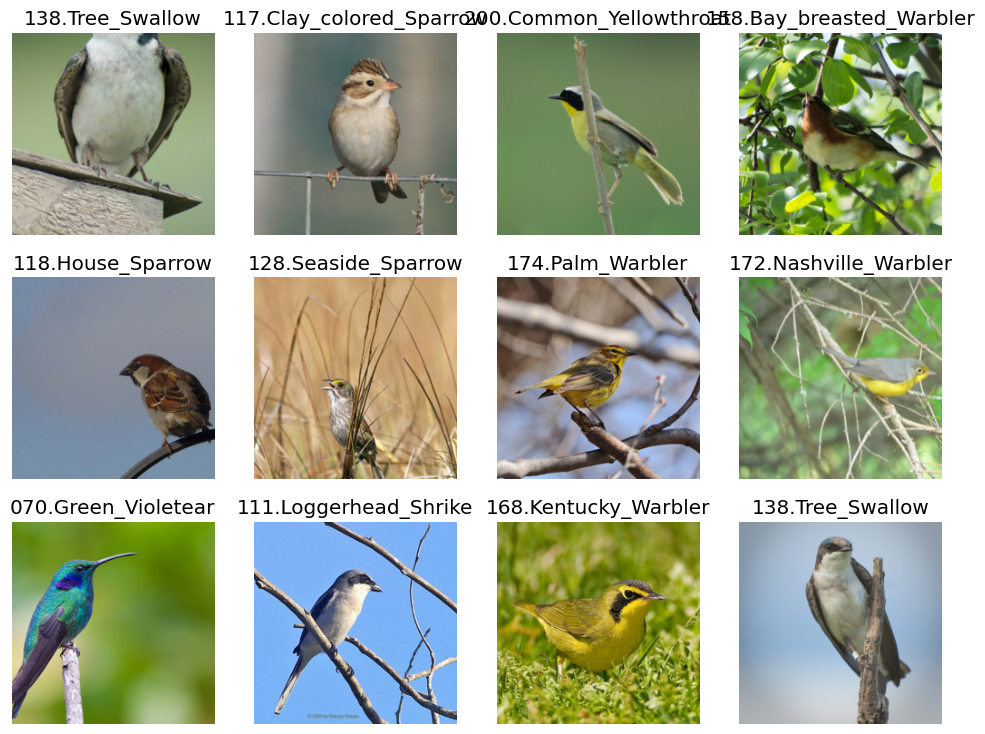

In [ ]:
CUB_200_2011 = DataBlock(
    # A CUBRIR POR EL ALUMNADO
    blocks=(ImageBlock, CategoryBlock),
    get_items=get_image_files,
    splitter=RandomSplitter(valid_pct=0.1, seed=42),
    get_y=parent_label,
    item_tfms=[Resize(224)]
)

dls = CUB_200_2011.dataloaders(path/'train', bs=128)

dls.show_batch(max_n=12)

print('Numero de ejemplos de entrenamiento (una vez descartados los de validacion):', len(dls.train_ds))
print('Numero de ejemplos de validacion:', len(dls.valid_ds))

Pasamos ahora a construir el modelo. Para ello se nos pide utilizar el modelo **efficientnet_b0** ya preentrenado.

Se nos pide modificar la cabecera a una que tenga global average pooling y una única fully-connected layer.

Además, extraemos el cuerpo del modelo, es decir, la parte relativa a las capas convolucionales y capas intermedias para extraer el número de características, que será el parámetro de entrada de la última y única capa FC.

Por último, construímos el modelo utilizando la función **vision_learner** que tiene como parámetros el conjunto de entrenamiento, el modelo efficient_net, al que seleccionamos su versión preentrenada, la cabecera personalizada y por último las métricas y función de pérdida típicas de un problema de clasificación, como son **accuracy** y **CrossEntropyFlat**.

In [ ]:
# A CUBRIR POR EL ALUMNADO

# Extraemos el cuerpo del modelo para tener el número de
# características de salida de la última capa del cuerpo.
modelo = models.efficientnet_b0(pretrained=True)
body = create_body(modelo)
num_features = num_features_model(body)

# Se construye la cabecera, con global average pooling
# y donde el número de características de salida del cuerpo
# es el número de características de entrada de la capa FC
custom_head = nn.Sequential(
                            nn.AdaptiveAvgPool2d((1,1)),
                            nn.Flatten(),
                            nn.Linear(num_features, 200))

# Se construye el modelo a partir de efficientnet_b0 preentrenada
# y custom head.
learn = vision_learner(dls,
                          models.efficientnet_b0,
                          loss_func=CrossEntropyLossFlat(),
                          metrics=accuracy,
                          custom_head = custom_head,
                          pretrained=True)

learn.summary()

/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=EfficientNet_B0_Weights.IMAGENET1K_V1`. You can also use `weights=EfficientNet_B0_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 136MB/s] 


Sequential (Input shape: 128 x 3 x 224 x 224)
Layer (type)         Output Shape         Param #    Trainable 
                     128 x 32 x 112 x 11 
Conv2d                                    864        False     
BatchNorm2d                               64         True      
SiLU                                                           
Conv2d                                    288        False     
BatchNorm2d                               64         True      
SiLU                                                           
____________________________________________________________________________
                     128 x 32 x 1 x 1    
AdaptiveAvgPool2d                                              
____________________________________________________________________________
                     128 x 8 x 1 x 1     
Conv2d                                    264        False     
____________________________________________________________________________
                     

Vamos ahora a hacer el fine_tune del modelo, con **1 freeze_epoch** y **10 épocas totales.**

epoch,train_loss,valid_loss,accuracy,time
0,5.003822,4.170947,0.193656,00:22


epoch,train_loss,valid_loss,accuracy,time
0,3.857985,3.878106,0.277129,00:28
1,3.488139,3.221071,0.387312,00:28
2,2.899707,2.447758,0.505843,00:28
3,2.263567,2.029788,0.552588,00:28
4,1.755980,1.772699,0.585977,00:30
5,1.381960,1.631467,0.590985,00:29
6,1.131624,1.556109,0.606010,00:29
7,0.964287,1.524307,0.599332,00:29
8,0.864037,1.514274,0.601002,00:29
9,0.821810,1.513356,0.597663,00:29


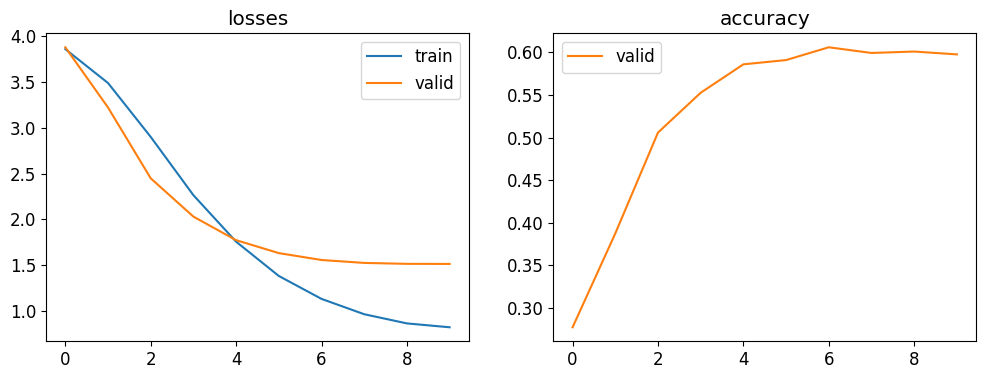

In [ ]:
learn.fine_tune(epochs=10, freeze_epochs=1)
learn.recorder.plot_metrics()

Observaciones:


*   La accuracy es bastante pobre ( 60% ). Esto puede deberse a que las clases de aves son muy parecidas y no hay tantos ejemplares por clase y como son 200 clases en total, el modelo no clasifica bien. Además, quizá se puede deber a las pocas épocas de fine_tuning, aunque el modelo está preentrenado de serie, pero es posible que no sean suficientes épocas de entrenamiento para el modelo con la nueva cabecera.
*   Como podemos ver, a partir de la época 4-5, el modelo tiende a sobreajustar. Esto se ve porque la función de pérdida sigue bajando mientras que la de valicación se estabiliza.



## <font color='blue'> Uso de Grad-CAM para analizar el comportamiento de redes convolucionales (1 pto)

<font color='blue'> Una vez entrenado el modelo, se debe aplicar Grad-CAM para visualizar los mapas de activación del **último bloque convolucional** (y solo de este último bloque). Es importante que el alumnado demuestre y explique que, efectivamente, está aplicando Grad-CAM sobre el último bloque convolucional.

<font color='blue'> Para ello, los alumnos deben emplear el paquete `grad-cam`: `!pip install grad-cam`. Se trata de una librería con métodos del estado del arte para dotar de explicabilidad a modelos de visión por computador. Se recomienda encarecidamente revisar con calma la documentación relativa a dicho paquete (https://jacobgil.github.io/pytorch-gradcam-book/introduction.html y https://github.com/jacobgil/pytorch-grad-cam) y basarse en los ejemplos allí indicados de cara a realizar la implementación. El alumnado debe emplear Grad-CAM con, al menos, $5$ imágenes de test, así como interpretar los resultados obtenidos.  

<font color='blue'> ¿En qué consiste Grad-CAM: cómo funciona y para qué sirve?

<font color='blue'> Referencia: https://arxiv.org/pdf/1610.02391.pdf

**Grad-CAM** ( Gradient-weighted Class Activation
Mapping ) es una herramienta de IA explicativa que pretende dar explicaciones visuales de los datos de una CNN para ver qué es lo que el modelo ha seleccionado para clasificar una imagen en una clase. Se encarga de usar el gradiente para generar una especie de mapas de calor que señalan esta información relevante en cuanto a la clasificación de la imagen.

In [ ]:
!pip install grad-cam

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.8/7.8 MB 53.9 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for grad-cam: filename=grad_cam-1.5.5-py3-none-any.whl size=44284 sha256=7f183c4517b09d6fab0f9bce61e1b41ddca4512b52b8e70eb09ba0859e173bf2
  Stored in directory: /root/.cache/pip/wheels/fb/3b/09/2afc520f3d69bc26ae6bd87416759c820a3f7d05c1a077bbf6
Successfully built grad-cam


Vamos a visualizar el modelo, para tener una visión del último bloque convolucional para poder después comprobar que estamos aplicando el algoritmo en esa capa.

In [ ]:
# A CUBRIR POR EL ALUMNADO
from pytorch_grad_cam import GradCAM, HiResCAM, ScoreCAM, GradCAMPlusPlus, AblationCAM, XGradCAM, EigenCAM, FullGrad
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
from pytorch_grad_cam.utils.image import show_cam_on_image
model = learn.model
print(model)

Sequential(
  (0): Sequential(
    (0): Sequential(
      (0): Conv2dNormActivation(
        (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
        (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (2): SiLU(inplace=True)
      )
      (1): Sequential(
        (0): MBConv(
          (block): Sequential(
            (0): Conv2dNormActivation(
              (0): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=32, bias=False)
              (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
              (2): SiLU(inplace=True)
            )
            (1): SqueezeExcitation(
              (avgpool): AdaptiveAvgPool2d(output_size=1)
              (fc1): Conv2d(32, 8, kernel_size=(1, 1), stride=(1, 1))
              (fc2): Conv2d(8, 32, kernel_size=(1, 1), stride=(1, 1))
              (activation): SiLU(inplace=True)
              (scale_activation): Sigm

Para acceder al último bloque convolucional, tenemos en cuenta que en model[0] se guarda el body y en model[1] el head. Además, hay otro sequential metido dentro del body por lo que realmente el último bloque convolucional estará en model[0][0][-1]

In [ ]:
print(model[0][0][-1])

Conv2dNormActivation(
  (0): Conv2d(320, 1280, kernel_size=(1, 1), stride=(1, 1), bias=False)
  (1): BatchNorm2d(1280, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (2): SiLU(inplace=True)
)


Si comprobamos con el último trozo de la respuesta del bloque de código anterior, vemos como este bloque es el que está justo antes del head. Vamos ahora a aplicar el algoritmo. Para ello debemos seguir los siguientes pasos:
1.  Definir las capas a las que queremos aplicar grad-CAM ( en nuestro caso model[0][0][-1].
2.  Tomar el conjunto de test y tomar cada imagen individual.
3.  Seleccionar 5 imágenes aleatorias.
4.  Pasamos esas imágenes a rgb.
5.  Aplicamos el algoritmo que nos proporciona el ejemplo referenciado.

In [ ]:

# Definimos las layers a las que se quiere aplicar Grad Cam
target_layers = [model[0][0][-1]]

# Tomamos el conjunto de test
test_dl = dls.test_dl(files_test)

# Descomponemos el conjunto de test en imagenes individuales. Para
# ello ChatGPT nos proporciona una funcion que toma cada batch y extrae
# cada imagen.
all_batches = list(test_dl)
all_images = []

for batch in all_batches:
    # batch puede ser un tuple (tensor,)
    if isinstance(batch, tuple) or isinstance(batch, list):
        batch = batch[0]  # extraer el tensor
    # batch: (batch_size, 3, 224, 224)
    for img in batch:
        all_images.append(img)

# Definimos un vector con indices del vector de imagenes a seleccionar
indices = [0, 50, 150, 182, 199]
selected_images = [all_images[i] for i in indices]

# Creamos el tensor de las imagenes
input_tensor = torch.stack(selected_images)
# We have to specify the target we want to generate the CAM for.
# En este caso seleccionamos que targets sea None para que gradCam
# sea el que decida que clase es más probable para cada imagen
targets = None

# Definimos una funcion para pasar el tensor a imagen. Esto es porque
# los tensores tienen dim ( C, H, W) y necesitamos (H, W, C).
# ChatGPT nos ha dado la parte de usar la cpu porque hay que pasar
# el tensor a cpu
def tensor_to_rgb(t):
    return t.cpu().permute(1,2,0).numpy()

rgb_imgs = [tensor_to_rgb(img) for img in selected_images]

# Aplicamos ahora el algoritmo, usando el ejemplo del enlace de referencia
visualization = []
# Construct the CAM object once, and then re-use it on many images.
with GradCAM(model=model, target_layers=target_layers) as cam:
  # You can also pass aug_smooth=True and eigen_smooth=True, to apply smoothing.
  grayscale_cam = cam(input_tensor=input_tensor, targets=targets)

  for i in range(5):
    visualization.append(show_cam_on_image(rgb_imgs[i],
                                           grayscale_cam[i],
                                           use_rgb=True))
  # You can also get the model outputs without having to redo inference
  model_outputs = cam.outputs


Finalmente, sabemos que el resultado de las predicciones se guarda en model_outputs. Podemos ahora tomar el resultado del algoritmo que se guarda en **visualization** y visualizarlo junto a las imágenes normales en **rgb_imgs** para sacar conclusiones. Además, sacamos con **dls.vocab** las etiquetas asociadas a cada imagen.

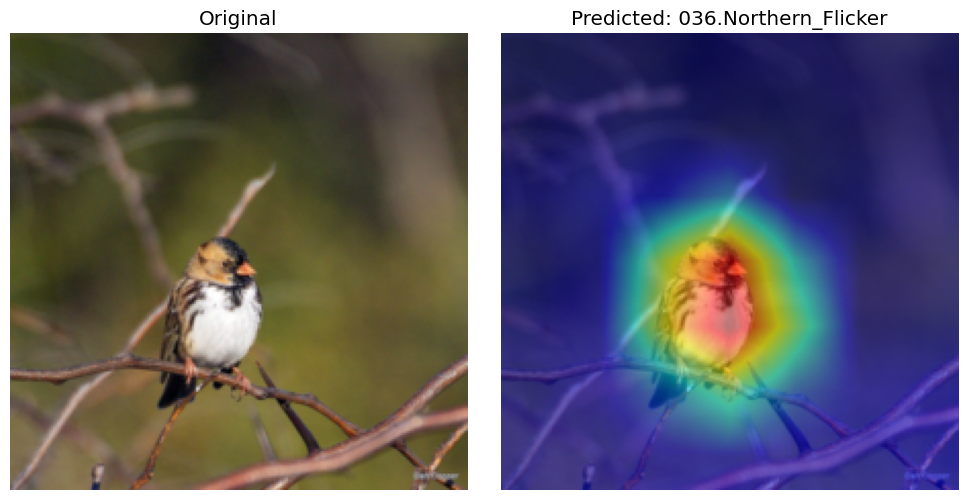

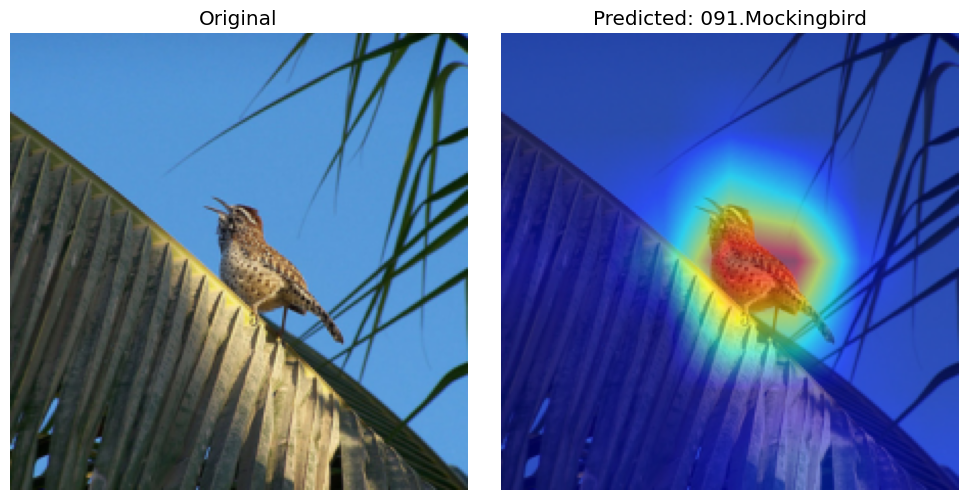

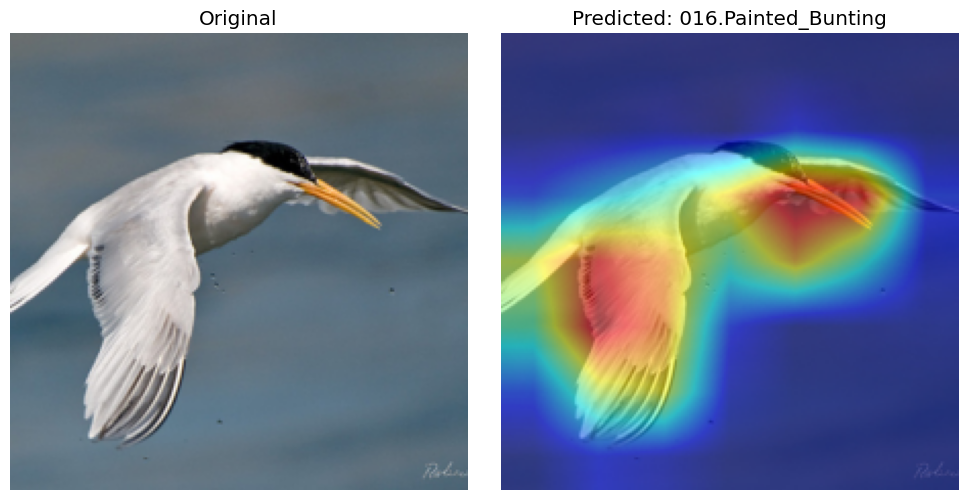

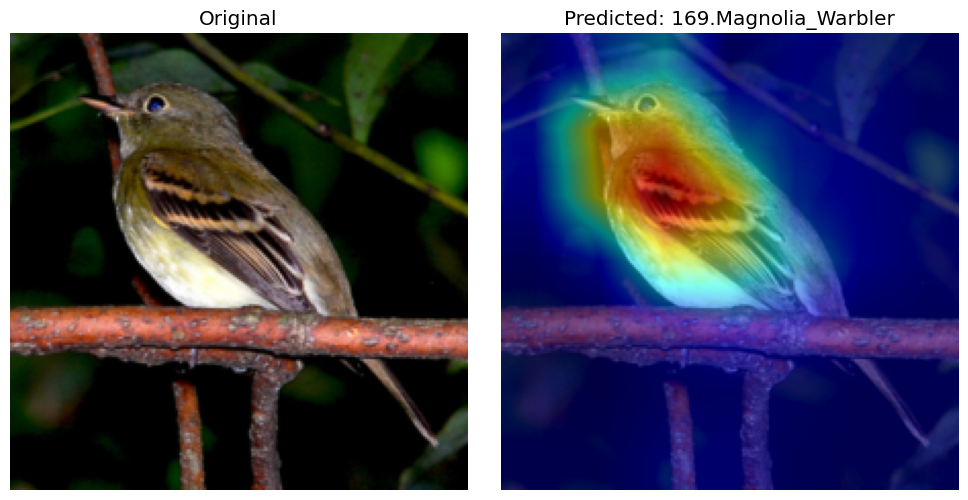

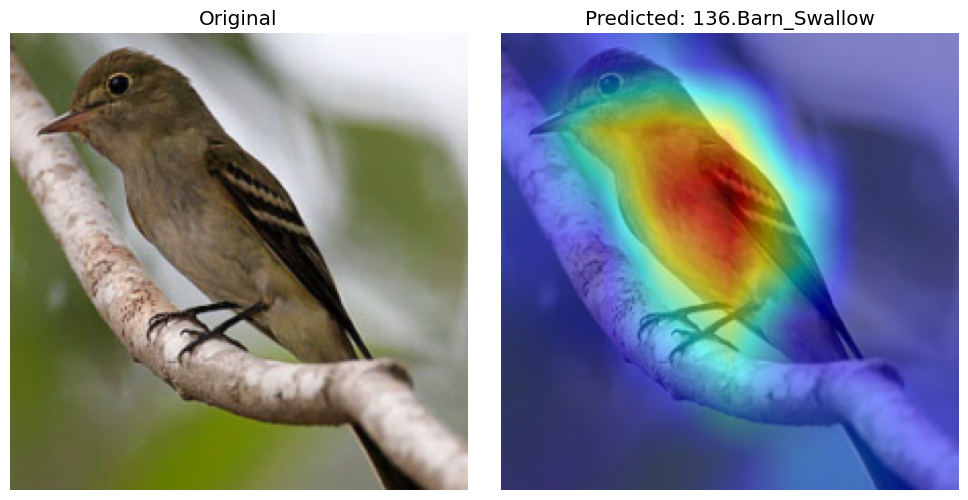

In [ ]:
preds = model_outputs.argmax(dim=1)
dls.vocab
pred_names = [dls.vocab[p] for p in preds]
for i in range(5):
  fig, axes = plt.subplots(1, 2, figsize=(10, 5))
  axes[0].imshow(rgb_imgs[i])
  axes[0].set_title("Original")
  axes[0].axis('off')
  axes[1].imshow(visualization[i])
  axes[1].set_title(f'Predicted: {pred_names[i]}')
  axes[1].axis('off')
  plt.tight_layout()
  plt.show()

Como podemos apreciar, grad-CAM nos indica qué partes ha seleccionado nuestro modelo efficient_net para clasificar cada imagen. En este caso se puede ver que se emplean elementos que un ser humano quizá también emplearía, como pueden ser formas y colores de pico muy distintas ( por ejemplo alargado o de otro color ) o patrones específicos en el plumaje.

## <font color='blue'> EfficientNet-B0 (0.25 ptos)

<font color='blue'> Intente profundizar un poco en la arquitectura empleada (EfficientNet-B0), así como la manera en que esta arquitectura, y otras de la familia EfficientNet, han sido generadas y las innovaciones clave que presentaron cuando fueron introducidas. Para responder esta pregunta se recomienda la lectura del artículo *Tan, Mingxing, and Quoc Le. "EfficientNet: Rethinking model scaling for convolutional neural networks." International conference on machine learning. PMLR, 2019.* https://proceedings.mlr.press/v97/tan19a/tan19a.pdf

<font color='blue'> Nota: resulta clave, tanto en este apartado como en todos los demás de la práctica, que el alumnado se exprese con claridad, utilizando sus propias palabras, y demostrando que entiende lo que está explicando.

El artículo se basa principalmente en el llamado **model scalling** para la construcción de nuevas CNN que proporcionen resultados mejores en tiempos y en accuracy que otras familias de redes.

Este escalado se basa en tres medidas, la profundidad (**d**) y el ancho (**w**) de la red y la resolución (**r**) de la imagen. Este escalado es de la siguiente forma:
*   **profundidad**: Se añaden más capas.
*   **ancho**: Se incrementa el número de canales de cada capa.
*   **resolución**: Se aumenta el tamaño de la imagen.

El artículo menciona como ha sido común el escalado de la profundidad y/o el ancho de la red y como esto ha sido común en familias como resnet para mejorar accuracy. Además, se menciona como recientemente se está empleando el escalado en resolución.

La idea principal es conseguir definir un método para escalar ConvNets de forma que obtengamos mejora en tiempo y en accuracy. Para ello se propone el método **compound scalling method**. En este método se busca establecer un balance de escalado en base a los tres parámetros. Parece tener sentido el hecho de que con una imagen de mayores dimensiones, necesitemos más capas y con más canales para que detecten mejor las características de los datos.

Todo comienza con una buena base que se debe escalar. Para ello el artículo presenta inicialmente una serie de restricciones a los parámetros. Se comenta además que los parámetros **d, w, r** dependen entre sí y que es complicado establecer los valores óptimos, por lo que clásicamente se optaba por escalar solo en una dimensión.

El problema de escalar sólo en profundidad, es que llega un punto en el que incrementamos el tiempo de ejecución sin una ganancia significativa en accuracy. En cuanto a la anchura, tenemos resultados parecidos. Se espera que a mayor ancho, se obtengan características más pequeñas, pero al igual que con la profundidad, llega un momento que aumentar el ancho no supone una mejora significativa. Para la resolución, sucede algo parecido, aunque quizá es menos notorio.

Antes de plantear el método exacto, se realiza una comparativa de accuracy y FLOPS con varios modelos con diferente d, w y r.

De estos dos puntos anteriores, se observa que:
1.    Escalar cualquier dimensión mejora el accuracy pero rápidamente esta ganancia se aplana en modelos grandes.
2.    Para obtener una mejor accuracy y eficiencia, es necesario establecer unos parámetros d, w y r balanceados.

Finalmente se propone el método, que usa un coeficiente global y un coeficiente asociado a cada parámetro de modo que d, w y r son el coeficiente local elevado al global, donde además se tiene una restricción entre los coeficientes locales ( coef_d x coef_w^2 x coef_r^2 entorno a 2 ).

Por último se nos presenta el modelo **EfficientNet_B0**. Este está formado por una red base formada por una capa Conv, varios bloques MBConv ( que no se especifica muy bien que son ) y por último una Capa Conv + Pooling + FC.

Para mejorar el modelo, se siguen dos pasos:
1.    Se fija el parámetro global $ϕ$ a 1 y se buscan los coeficientes locales a cada parámetro en base a las restricciones anteriores probando una combinación de parámetros. Para EN-B0, se toma α = 1.2,β = 1.1,γ = 1.15, que son los coeficientes locales a profundidad, ancho y resolución respectivamente.
2.  Una vez obtenidos estos parámetros, se juega con $ϕ$ para obtener los distintos modelos de EfficientNet.

Estos modelos proporcionan resultados en accuracy más altos y de forma más eficiente que otras redes tradicionales.

## <font color='blue'> Sobre los límites de Grad-CAM y herramientas similares (0.25 ptos)

<font color='blue'> Para finalizar el ejercicio, revise el artículo *Ghassemi, Marzyeh, Luke Oakden-Rayner, and Andrew L. Beam. "The false hope of current approaches to explainable artificial intelligence in health care." The lancet digital health 3.11 (2021): e745-e750.* (https://www.thelancet.com/journals/landig/article/PIIS2589-7500(21)00208-9/fulltext). ¿Por qué los autores hablan de "falsa esperanza"? Realice un breve análisis crítico del artículo, explicando con sus propias palabras las principales conclusiones/reflexiones del mismo.

Este artículo trata sobre todo de los límites de la IA explicativa en un ejemplo particular de la medicina. Es innegable la utilidad de algoritmos de machine learning en cualquier ámbito de la sociedad y la medicina es un área donde más se está enfocando el uso de la IA.
La IA se ve por muchos sectores de población como una herramienta " caja negra ", que significa que para este grupo de gente no se puede comprender o interpretar el cómo funcionan estos algoritmos. Esto supone un problema porque muchos profesionales no necesitan solo resultados, sino que se necesita conocer el por qué. Entre estos profesionales encontramos médicos, abogados, científicos... De aquí nace el concepto de IA explicativa.

Por ejemplo, el artículo comienza con una imagen de una radiografía de tórax con el fin de detectar pneumonía, a la que se aplica un algoritmo que debe ser similar a grad-CAM. Pese a tener una gran accuracy en cuanto a la predicción del modelo, vemos que el heatmap que genera el algoritmo, se marcan en las zonas más importantes información que es tanto muy útil como no útil desde el punto de vista de un profesional humano. Esto es claramente un problema, pues el algoritmo está usando partes que no usaría un humano para clasificar un asunto tan grave como una enfermedad.

Por supuesto, también se utilizan partes que el ser humano cree vitales para detectar en este caso la enfermedad. Esto lleva a plantear una pregunta. Si vemos varias explicaciones de un modelo para clasificar algo de una forma u otra ¿ Tomamos la que más nos conviene e ignoramos las otras ? Esto es un error, porque realmente la explicabilidad vuelve a ser responsabilidad del humano, es decir, tiene que decidir qué interpretación de la IA es correcta y cuál no.

Además, el hecho de que la IA decida fijarse en ciertas regiones que no deberían de influir en la decisión, hace que las decisiones que tomemos tomen sesgos peligrosos.

Todos estos hechos hacen que haya que tener cuidado con la IA explicativa. Se pone como ejemplo en el artículo el hecho de que en la medicina existen otros tipos de métodos black box, como ciertos fármacos que se desconoce ciertos aspectos de su funcionamiento pero sabemos que son útiles por pruebas aleatorias controladas. Debemos de tomar la IA como tal, donde sean los profesionales los que tomen decisiones en última instancia, donde la IA juega el papel de modelos eficaces y probados, dejando la parte racional a profesionales. La IA explicativa no debería de desecharse, sino que debería servir para mejorar el rendimiento de los modelos y para detectar decisiones que el ser humano no tomaría ante algún dato, además de eliminar sesgos.

**¿Por qué se habla entonces de falsa esperanza?** Pues porque como hemos visto, la IA tiene fallos al nivel de explicabilidad, lo que sumado a que las personas tienden a sobreconfiar en programas informáticos, puede llevar a que las personas dejen la parte de toma de decisiones en estas herramientas lo que en tareas de cierto riesgo pueden llevar a errores fatales. En conclusión, debemos utilizar estas herramientas como modelos probados de alto rendimiento y eficacia, pero dejar que los profesionales sean los que tomen decisiones en base a conclusiones humanas.